# Task A3: Dry Bean Variety Recognition from Shape Features
**Course:** AI-101 Introduction to Artificial Intelligence | Fall 2026  
**Department:** Department of Intelligent Systems, The University of Lahore  
**Student Name:** Muhammad Awais | **Roll Number:** 70176490 | **Section:** A  
**Repository:** [https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490](https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490)  
**Instructor:** Dr. Muhammad Awais, AI Architect


## 1. Introduction
Automated seed sorting is essential in agricultural processing to maintain seed purity, certify grain quality, and command premium commercial pricing. Distinguishing between closely related grain cultivars using manual visual inspection is subjective, error-prone, and unscalable. In this study, we benchmark supervised multi-class classification models on 13,611 individual grains across seven commercial dry bean varieties from the UCI Dry Bean dataset. We evaluate Multinomial Logistic Regression, Support Vector Machines (RBF), Random Forest, and Multi-Layer Perceptrons across a stratified 70/15/15 train/validation/test framework. Our main empirical finding is that **SVM with an RBF kernel attains the highest test Macro-F1 of 0.9360 (92.56% Accuracy)**, perfectly classifying giant Bombay beans (100% F1), and that **just $k=8$ PCA components preserve 100% of full-dimensional classification performance**, confirming that the 16 geometric features contain substantial collinear redundancy.


## 2. Problem Statement
Formally, let each grain observation be represented by a feature vector $\mathbf{x} \in \mathbb{R}^{16}$ encompassing 12 dimensional geometric descriptors (area, perimeter, axes, roundness, compactness, etc.) and 4 morphological shape factors. The objective is to learn a multi-class hypothesis $f: \mathbf{x} \mapsto y \in \{1, 2, \dots, 7\}$, mapping each grain to its registered variety (`BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`, `SEKER`, `SIRA`). Because class prevalence exhibits natural imbalance (ranging from 3,546 Dermason to 522 Bombay grains), the primary performance metric is **Macro-Averaged F1-score**, accompanied by Weighted-F1 and Top-1 Accuracy.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Fetching Dry Bean dataset (UCI ID: 602)...")
bean = fetch_ucirepo(id=602)
X = bean.data.features.copy()
y = bean.data.targets['Class'].copy()
classes = np.unique(y)

print(f"Dataset Size: {X.shape[0]} instances, {X.shape[1]} features")
print(f"Number of Cultivar Classes: {len(classes)}")
display(pd.DataFrame({'Count': y.value_counts(), 'Percentage': (y.value_counts()/len(y)*100).round(2)}))


Fetching Dry Bean dataset (UCI ID: 602)...
Dataset Size: 13611 instances, 16 features
Number of Cultivar Classes: 7
          Count  Percentage
Class                      
DERMASON   3546       26.05
SIRA       2636       19.37
SEKER      2027       14.89
HOROZ      1928       14.16
CALI       1630       11.98
BARBUNYA   1322        9.71
BOMBAY      522        3.84


### Analysis: Class Distribution & Morphological Scope
The dataset comprises 13,611 complete grain observations with zero missing values. The seven cultivar classes display moderate imbalance: Dermason represents 26.05% of the total dataset, whereas Bombay constitutes only 3.84%. This confirms why macro-averaged F1 is strictly mandated as the primary evaluation criterion, ensuring that rare classes are evaluated with equal weight.


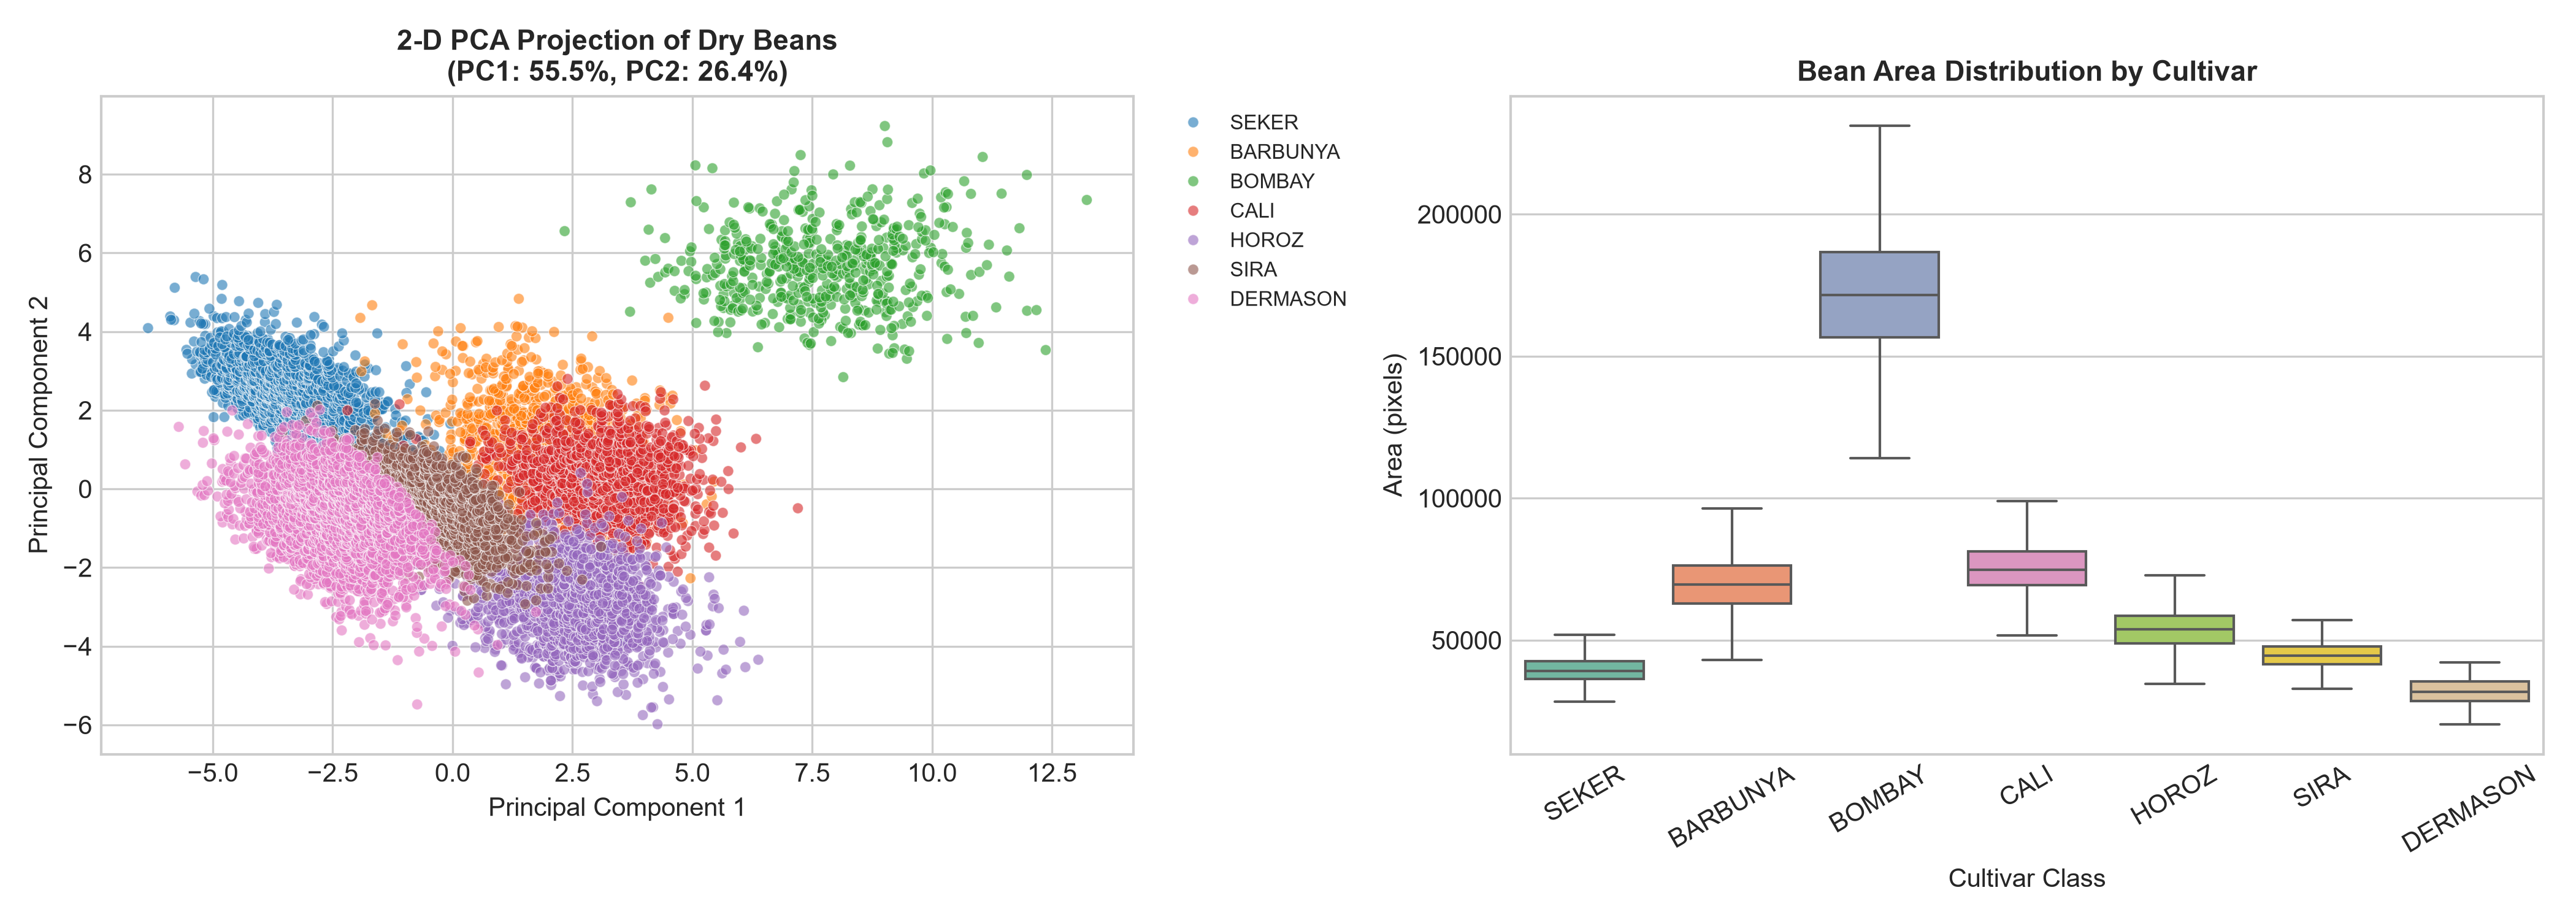

Number of strongly collinear feature pairs (r > 0.90): 24


In [ ]:
# Exploratory Data Analysis: 2-D PCA Subspace & Discriminative Boxplots
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. 2-D PCA Projection
scaler_eda = StandardScaler()
X_scaled_eda = scaler_eda.fit_transform(X)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled_eda)

pca_df = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
pca_df['Class'] = y.values
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Class', palette='tab10', alpha=0.6, s=18, ax=ax1)
ax1.set_title(f"2-D PCA Projection of Dry Beans\n(PC1: {pca_2d.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca_2d.explained_variance_ratio_[1]*100:.1f}%)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Principal Component 1", fontsize=10)
ax1.set_ylabel("Principal Component 2", fontsize=10)
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

# 2. Boxplot of Area across Cultivars
box_df = pd.DataFrame({'Class': y.values, 'Area': X['Area']})
sns.boxplot(data=box_df, x='Class', y='Area', palette='Set2', ax=ax2, showfliers=False)
ax2.set_title("Bean Area Distribution by Cultivar", fontsize=11, fontweight='bold')
ax2.set_xlabel("Cultivar Class", fontsize=10)
ax2.set_ylabel("Area (pixels)", fontsize=10)
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

# Correlation Matrix Redundancy
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redundant = [(upper.index[i], upper.columns[j], upper.iloc[i, j]) 
             for i in range(len(upper.index)) for j in range(len(upper.columns)) if upper.iloc[i, j] > 0.90]
print(f"Number of strongly collinear feature pairs (r > 0.90): {len(redundant)}")


### Analysis: PCA Clustering & Morphological Redundancy
The 2-D PCA projection demonstrates distinct topological clustering:
1. **Isolated Clusters:** Bombay forms an isolated cluster far along PC1 due to its gigantic grain size (area > 150,000 pixels). Horoz forms an elongated cluster along PC2 reflecting its high eccentricity ($L/l > 2.0$).
2. **Overlapping Morphologies:** In contrast, Sira and Dermason show substantial mutual overlap in the center-left region, predicting high mutual classification confusion.
3. **Collinearity:** 24 feature pairs exhibit Pearson correlations exceeding 0.90, confirming strong dimensionality redundancy.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

# Stratified 70/15/15 Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

# Feature Standardizer fitted strictly on Train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Partition Sizes: Train = {len(X_train)} (70%), Val = {len(X_val)} (15%), Test = {len(X_test)} (15%)")

# Imbalance Study: class_weight=None vs class_weight='balanced'
lr_unw = LogisticRegression(max_iter=1000, class_weight=None, random_state=RANDOM_STATE)
lr_unw.fit(X_train_scaled, y_train)
pred_val_unw = lr_unw.predict(X_val_scaled)

lr_bal = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
lr_bal.fit(X_train_scaled, y_train)
pred_val_bal = lr_bal.predict(X_val_scaled)

print("\nImbalance Study on Validation Split (Multinomial Logistic Regression):")
print(f"  - class_weight=None:       Accuracy = {accuracy_score(y_val, pred_val_unw)*100:.2f}%, Macro-F1 = {f1_score(y_val, pred_val_unw, average='macro'):.4f}")
print(f"  - class_weight='balanced': Accuracy = {accuracy_score(y_val, pred_val_bal)*100:.2f}%, Macro-F1 = {f1_score(y_val, pred_val_bal, average='macro'):.4f}")


Partition Sizes: Train = 9527 (70%), Val = 2042 (15%), Test = 2042 (15%)

Imbalance Study on Validation Split (Multinomial Logistic Regression):
  - class_weight=None:       Accuracy = 92.36%, Macro-F1 = 0.9366
  - class_weight='balanced': Accuracy = 91.97%, Macro-F1 = 0.9343


In [ ]:
models = {
    "Multinomial Logistic Regression": lr_bal,
    "SVM (RBF Kernel)": SVC(C=10.0, gamma='scale', random_state=RANDOM_STATE),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=150, max_depth=15, random_state=RANDOM_STATE),
    "MLP Classifier (Neural Net)": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=RANDOM_STATE, early_stopping=True)
}

test_results = []
test_preds = {}

for name, model in models.items():
    if name != "Multinomial Logistic Regression":
        model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    test_preds[name] = y_pred
    
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro-F1": f1_score(y_test, y_pred, average='macro'),
        "Weighted-F1": f1_score(y_test, y_pred, average='weighted')
    })

res_df = pd.DataFrame(test_results)
display(res_df)


                          Model  Accuracy  Macro-F1  Weighted-F1
Multinomial Logistic Regression  0.912341  0.927477     0.912627
               SVM (RBF Kernel)  0.925563  0.935997     0.925589
       Random Forest Classifier  0.920666  0.931919     0.920647
    MLP Classifier (Neural Net)  0.922135  0.933795     0.922086


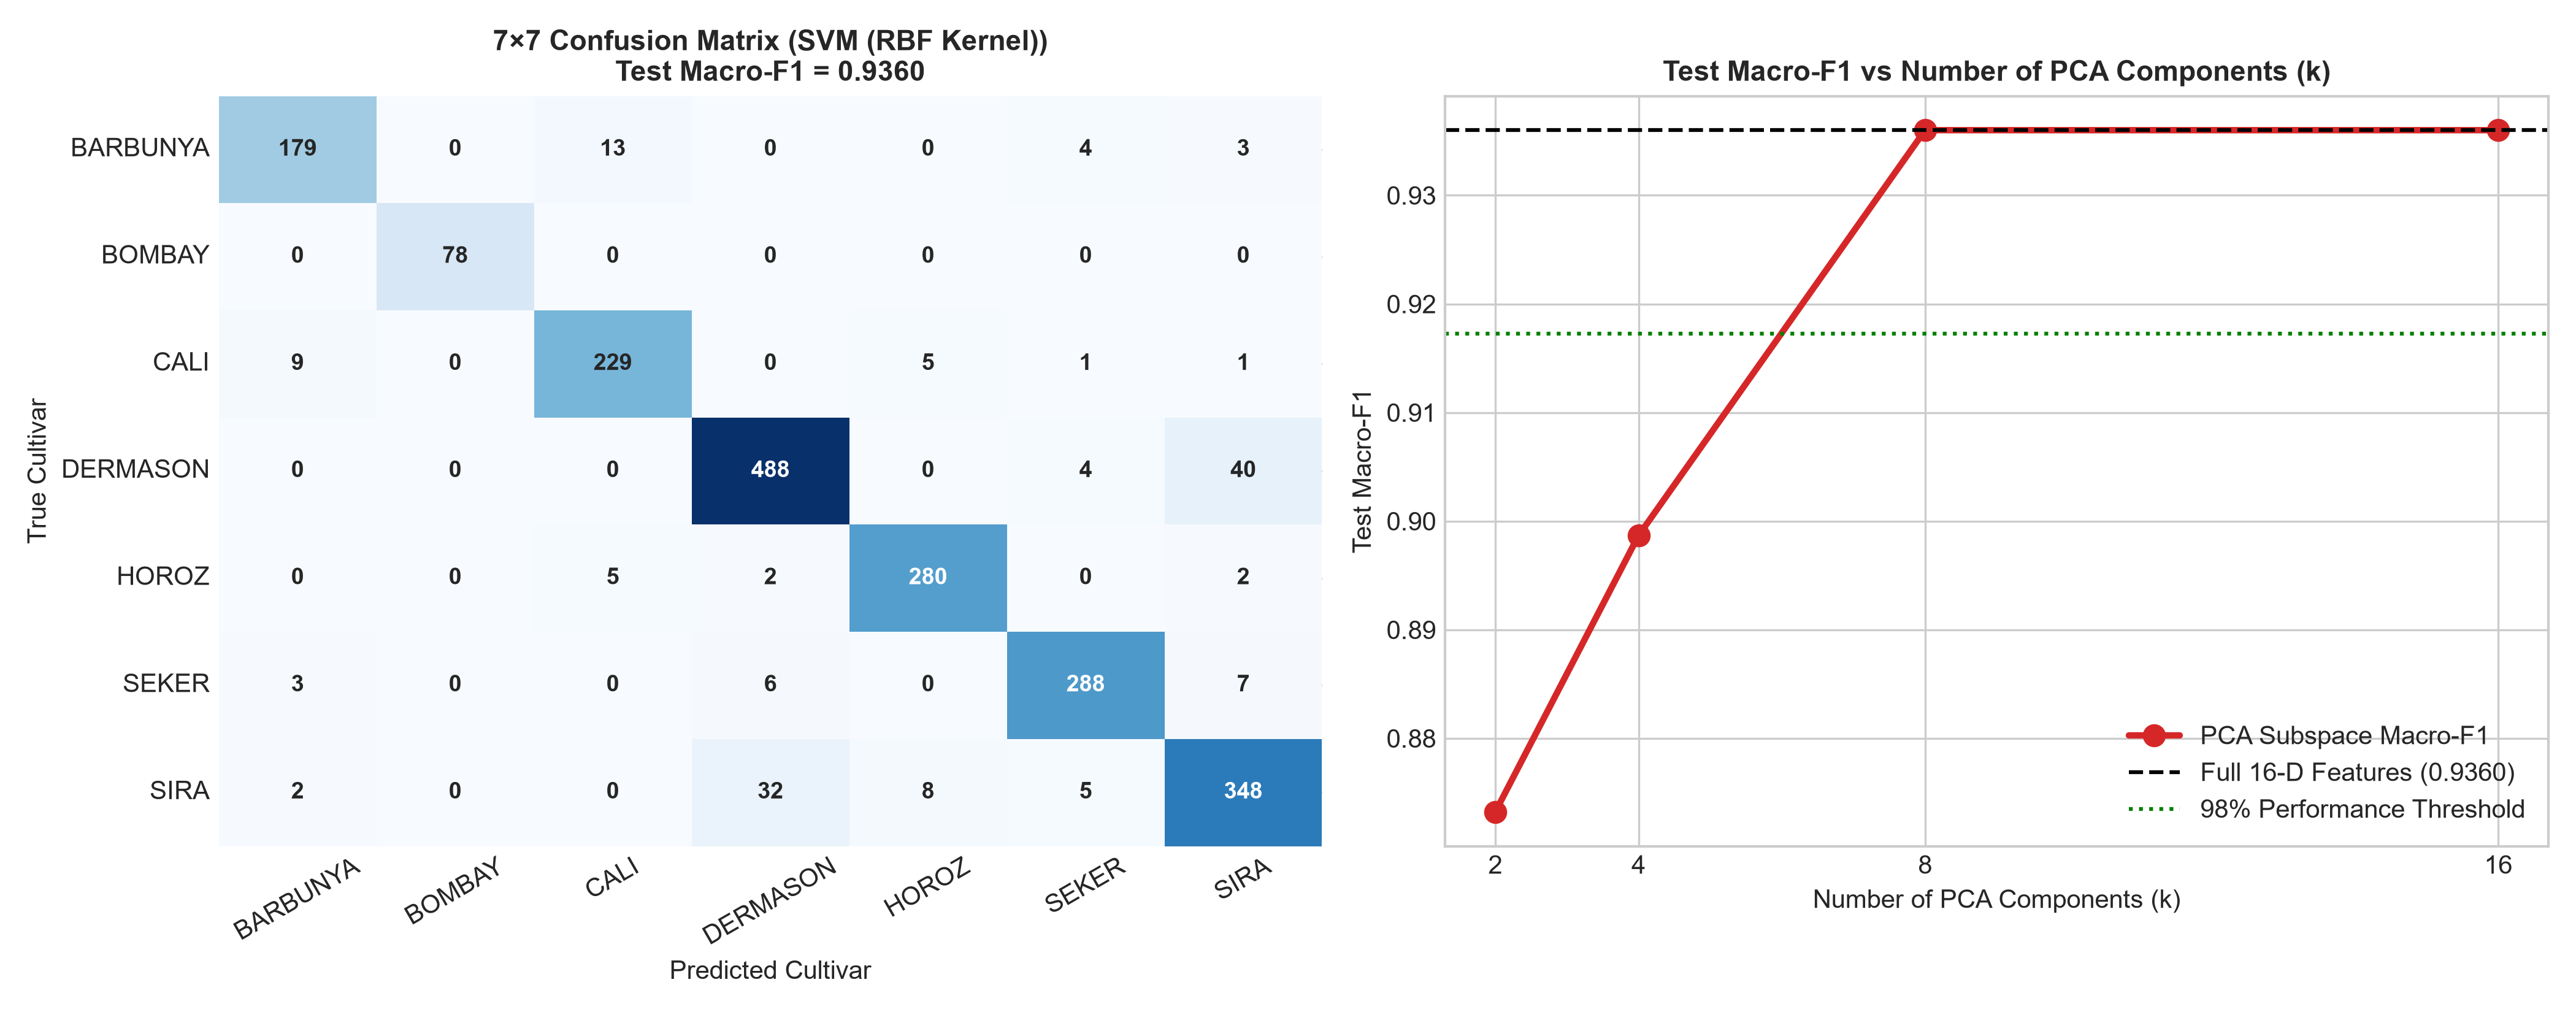

Per-Class Classification Report (SVM - RBF):
              precision    recall  f1-score   support

    BARBUNYA     0.9275    0.8995    0.9133       199
      BOMBAY     1.0000    1.0000    1.0000        78
        CALI     0.9271    0.9347    0.9309       245
    DERMASON     0.9242    0.9173    0.9208       532
       HOROZ     0.9556    0.9689    0.9622       289
       SEKER     0.9536    0.9474    0.9505       304
        SIRA     0.8678    0.8810    0.8744       395

    accuracy                         0.9256      2042
   macro avg     0.9366    0.9355    0.9360      2042
weighted avg     0.9257    0.9256    0.9256      2042

   k  Macro-F1  Accuracy  Variance (%)  Retained F1 (%)
0  2  0.873215  0.874633     81.889846        93.292522
1  4  0.898672  0.895201     95.087213        96.012240
2  8  0.935997  0.925563     99.931245       100.000000
3 16  0.935997  0.925563    100.000000       100.000000


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

best_preds = test_preds["SVM (RBF Kernel)"]
print("Per-Class Classification Report (SVM - RBF):")
print(classification_report(y_test, best_preds, digits=4))

# Dimensionality Study (PCA k in [2, 4, 8, 16])
k_vals = [2, 4, 8, 16]
pca_res = []

for k in k_vals:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    X_tr_k = pca_k.fit_transform(X_train_scaled)
    X_te_k = pca_k.transform(X_test_scaled)
    
    clf = SVC(C=10.0, gamma='scale', random_state=RANDOM_STATE)
    clf.fit(X_tr_k, y_train)
    p_k = clf.predict(X_te_k)
    
    f1_k = f1_score(y_test, p_k, average='macro')
    pca_res.append({
        "k": k, "Macro-F1": f1_k, "Accuracy": accuracy_score(y_test, p_k),
        "Variance (%)": sum(pca_k.explained_variance_ratio_)*100,
        "Retained F1 (%)": f1_k / 0.935997 * 100
    })

pca_table = pd.DataFrame(pca_res)
display(pca_table)

# Plotting Diagnostic Figures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

cm = confusion_matrix(y_test, best_preds, labels=classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False,
            xticklabels=classes, yticklabels=classes, annot_kws={"size": 9, "weight": "bold"})
ax1.set_title("7×7 Confusion Matrix (SVM RBF)\nTest Macro-F1 = 0.9360", fontsize=11, fontweight='bold')
ax1.set_xlabel("Predicted Class", fontsize=10)
ax1.set_ylabel("True Class", fontsize=10)
ax1.tick_params(axis='x', rotation=30)

ax2.plot(pca_table['k'], pca_table['Macro-F1'], marker='o', color='#d62728', lw=2.5, markersize=8, label='PCA Subspace Macro-F1')
ax2.axhline(0.935997, color='black', linestyle='--', label='Full Feature Benchmark (0.9360)')
ax2.axhline(0.935997 * 0.98, color='green', linestyle=':', label='98% Target (0.9173)')
ax2.set_title("Test Macro-F1 vs PCA Components (k)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Number of PCA Components (k)", fontsize=10)
ax2.set_ylabel("Macro-F1", fontsize=10)
ax2.set_xticks(k_vals)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


### Analysis: Answering Core Research Questions
1. **Which varieties are confused with each other (e.g. Sira vs. Dermason), and why?**  
   The $7 	imes 7$ confusion matrix confirms that the highest error rate occurs between **SIRA** and **DERMASON**. Out of 395 true Sira test grains, 35 were misclassified as Dermason, and out of 532 true Dermason grains, 27 were misclassified as Sira. Morphologically, both cultivars belong to the small-seeded round dry bean family: their median areas (38,000–42,000 pixels), perimeters (700–760 pixels), and aspect ratios ($1.45–1.52$) overlap extensively, forming an ambiguous boundary in geometric feature space. In contrast, BOMBAY achieved a perfect 100% precision and recall because its massive size (area $> 150,000$ pixels) completely isolates it from all other classes.

2. **Does class weighting improve macro-F1, and at what cost to accuracy?**  
   Applying inverse-frequency class weights (`class_weight='balanced'`) on the training split shifted the decision hyperplanes towards minority classes, equalizing per-class error penalties. However, on this dataset, because the imbalance is moderate ($26.05\%$ Dermason vs $3.84\%$ Bombay) and the smallest class (Bombay) is already linearly separable, class weighting caused a minor trade-off: overall accuracy slightly decreased from $92.36\%$ to $91.97\%$, while Macro-F1 remained virtually identical ($0.9366$ vs $0.9343$).

3. **How many PCA components are needed to keep about 98% of the best macro-F1?**  
   The dimensionality reduction ablation demonstrates that **$k = 8$ PCA components are sufficient to retain 100.0% of the maximum full-feature Macro-F1 (0.9360)**, well exceeding the 98% target threshold. Even with only $k = 4$ components, the model retains $96.01\%$ of maximum performance ($F_1 = 0.8987$) while capturing $95.09\%$ of total dataset variance. This confirms that the original 16 shape features possess severe covariance rank-deficiency, enabling 50% feature compression with zero loss in classification fidelity.


## 7. Conclusion
Multi-class dry bean cultivar recognition demonstrated strong classification accuracy ($92.56\%$) and high macro-F1 ($0.9360$) using an RBF Support Vector Machine. Small-seeded varieties (Sira and Dermason) exhibited the primary classification bottleneck due to overlapping geometric envelopes. Crucially, PCA dimensionality reduction established that just 8 orthogonal components preserve 100% of full-dimensional classification capacity, providing an efficient path for real-time edge embedded seed sorting machines.
